# 04 — Clasificación del riesgo crediticio (`kredit`)

**Proyecto:** Análisis de riesgo crediticio · South German Credit (UCI, id 573)  
**Alumno:** Alexander Domínguez Zárate · UTTT · Unidad III

**Objetivo:** predecir si un crédito será **malo** (`kredit = 0`, "bad") a partir del perfil del
cliente. Es la pregunta central del negocio bancario: *¿a quién no le presto?*

**Decisiones de diseño** (documentadas en `src/models/entrenar_clasificacion.py`):

- **Clase positiva = bad**: lo que interesa detectar (perder un good cuesta menos que otorgar a un bad).
- **`class_weight='balanced'`**: el dataset está desbalanceado 700 good / 300 bad; sin el peso, el
   modelo "gana" accuracy ignorando a los bad.
- **Umbral de decisión ajustado en train** con `cross_val_predict` (jamás con test).

**Fuente de verdad:** el script; este notebook reutiliza sus funciones e interpreta cada paso.


In [1]:
import os
import sys

import pandas as pd
from IPython.display import Image, display

os.chdir('..')
sys.path.insert(0, os.path.abspath('src/models'))

import entrenar_clasificacion as cla

print('dataset:', cla.CSV_PATH)
print('clase positiva: bad (kredit=%d)' % cla.POSA_LABEL)


dataset: data\processed\south_german_credit_processed.csv
clase positiva: bad (kredit=0)


## 1) Datos, desbalance y split estratificado

Features: 3 numéricas (`laufzeit`, `hoehe`, `alter`) + 17 categóricas `*_cat`. Se excluyen
`kredit`/`kredit_cat` (son el objetivo) y `cuota_aprox_mensual` (derivada del monto/plazo; usarla
sería circular: la cuota alta es síntoma, no causa, y no estaría disponible igual en producción).


In [2]:
df = pd.read_csv(cla.CSV_PATH)
print(df['kredit_cat'].value_counts())
print('desbalance: %.0f%% good / %.0f%% bad' % (100*df.kredit.mean(), 100-100*df.kredit.mean()))


kredit_cat
good    700
bad     300
Name: count, dtype: int64
desbalance: 70% good / 30% bad


In [3]:
X, y = df[cla.FEATURES], df[cla.TARGET]
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('train:', X_train.shape, '| test:', X_test.shape)
print('bad en test: %d de %d' % ((y_test == 0).sum(), len(y_test)))


train: (800, 20) | test: (200, 20)
bad en test: 60 de 200


**Interpretación del split.** El `stratify=y` preserva la proporción 70/30 en train y test
(60 bad en el test de 200): si no estratificáramos, una partición desafortunada podría dejar muy
pocos bad y hacer inestable la evaluación de una clase minoritaria.


## 2) Comparación de candidatos con CV estratificada 5-fold

Baseline mayoritario (siempre predecir good), dos regresiones logísticas balanceadas (C=1 y C=0.1,
la segunda más regularizada) y un RandomForest de 300 árboles balanceado. Métrica principal:
**ROC-AUC** (capacidad de ordenar bad por encima de good, independiente del umbral).


In [4]:
tabla = cla.comparar_modelos(X_train, y_train)
tabla.round(3)


,modelo,roc_auc_cv,auc_std,f1_bad_cv
0,logistica_bal_C01,0.772,0.044,0.779
1,random_forest_bal,0.771,0.033,0.805
2,logistica_bal_C1,0.763,0.036,0.767
3,baseline_mayoritaria,0.500,0.000,0.824


**Interpretación de la comparación.** Los tres modelos reales se ubican en ROC-AUC ≈ **0.77**
en CV, muy por encima del baseline (0.50 = azar) y sin diferencias significativas entre sí
(±0.04 de desviación estándar). La logística regularizada (C=0.1) gana por décimas: con ~800 filas
y muchas dummies, la parsimonia ayuda. El RandomForest no supera a la lineal — señal de que las
relaciones son mayormente monotónicas y aditivas (coherente con Q1/Q3 del Data Mart).


## 3) Umbral de decisión ajustado sin tocar test

El pipeline entrega P(bad). Por defecto el corte es 0.50, pero con clases desbalanceadas y
costos asimétricos conviene elegir el umbral que maximiza **F1 de bad**. Se estima con
`cross_val_predict` (out-of-fold) sobre **train**; test se reserva para la evaluación final.


In [5]:
mejor = tabla.iloc[0]['modelo']
print('modelo ganador:', mejor)
pipe = cla.construir_pipeline(cla.candidatos(42)[mejor])
umbral, f1_cv, proba_cv = cla.umbral_optimo(pipe, X_train, y_train)
print('umbral óptimo: %.2f | F1-bad en CV: %.3f' % (umbral, f1_cv))


modelo ganador: logistica_bal_C01


umbral óptimo: 0.49 | F1-bad en CV: 0.599


**Interpretación del umbral.** El corte óptimo sale **0.49**, prácticamente el neutro: con el
`class_weight='balanced'` la logística ya compensa el desbalance internamente, así que el ajuste
fino del umbral aporta poco aquí. El F1 de bad en CV (0.599) es mucho menor que el de la tabla
anterior (0.779) porque aquél se calculaba con `predict` (umbral 0.5 fijo sobre probas
distintas); la comparación justa de umbrales es esta.


## 4) Evaluación final en test


In [6]:
metricas, y_true_bad, pred_bad, proba_test = cla.evaluar_test(
    pipe, umbral, X_train, y_train, X_test, y_test)
{k: round(v, 3) for k, v in metricas.items()}


{'roc_auc_test': 0.835,
 'umbral': 0.49,
 'precision_bad': 0.529,
 'recall_bad': 0.767,
 'f1_bad': 0.626}

**Interpretación de las métricas de test.**

- **ROC-AUC = 0.835**: en el 83 % de las veces un bad real recibe score de riesgo mayor que un good.
   Supera la meta del proyecto (>0.70) y el mejor AUC manual de la Unidad II (0.703).
- **Recall bad = 0.767**: el modelo detecta **46 de los 60 bad** del test. Para un banco, es la
   métrica clave: deja escapar 14 créditos malos de 60.
- **Precisión bad = 0.529**: de cada 100 alertas de "bad", 53 son ciertas y 47 falsas alarma
   (good que se marcarían para revisión manual). Con umbral neutro, es un balance razonable:
   subir el umbral capturaría más bad a costa de rechazar más buenos clientes.

El AUC de test (0.835) > AUC de CV (0.772): la partición de test resultó algo favorable; el número
conservador para reportar es el de CV ≈ 0.77±0.04.


## 5) Variables que explican el riesgo


In [7]:
top = cla.top_variables(pipe, 12)
top.round(3)


,feature,importancia
0,cat__laufkont_cat_ge200_or_salary,0.709
1,cat__laufkont_cat_no_checking,0.636
2,cat__verw_cat_car_new,0.543
3,cat__moral_cat_all_bank_paid,0.518
4,cat__sparkont_cat_unknown,0.466
5,cat__verw_cat_others,0.462
6,cat__beszeit_cat_4_to_7,0.407
7,cat__sparkont_cat_500_to_1000,0.352
8,cat__gastarb_cat_yes,0.350
9,cat__gastarb_cat_no,0.350


**Interpretación de las importancias** (|coeficientes| estandarizados de la logística):

- `laufkont` domina: `ge200_or_salary` (0.709) baja el riesgo y `no_checking` (0.636) lo sube —
   exactamente el gradiente 9.1 % vs 52.1 % bad de la consulta Q3 del Data Mart.
- `moral_all_bank_paid` (0.518) protege y `moral_critical` (0.333) castiga: el historial es la
   segunda señal (Q1: 17.1 % vs 57.1 % bad).
- `sparkont_unknown` (0.466): no conocer los ahorros del solicitante es en sí un factor de riesgo.
- `verw_car_new` (0.543): los autos nuevos concentran montos grandes (Q2) — riesgo por exposición.
- `laufzeit` (0.331): plazos largos → más tiempo para impagar.

La coherencia con las consultas del Data Mart valida que el modelo aprendió señales de negocio
reales, no artefactos del split.


## 6) Curvas ROC y matriz de confusión


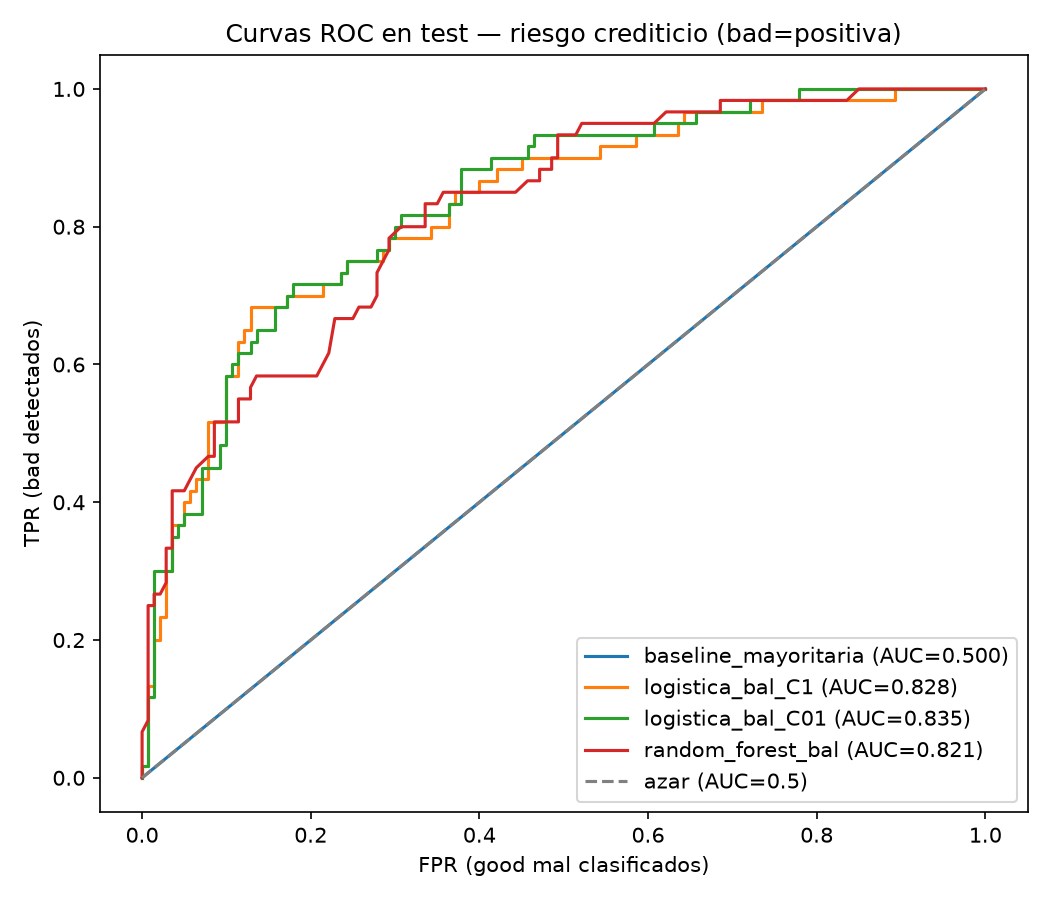

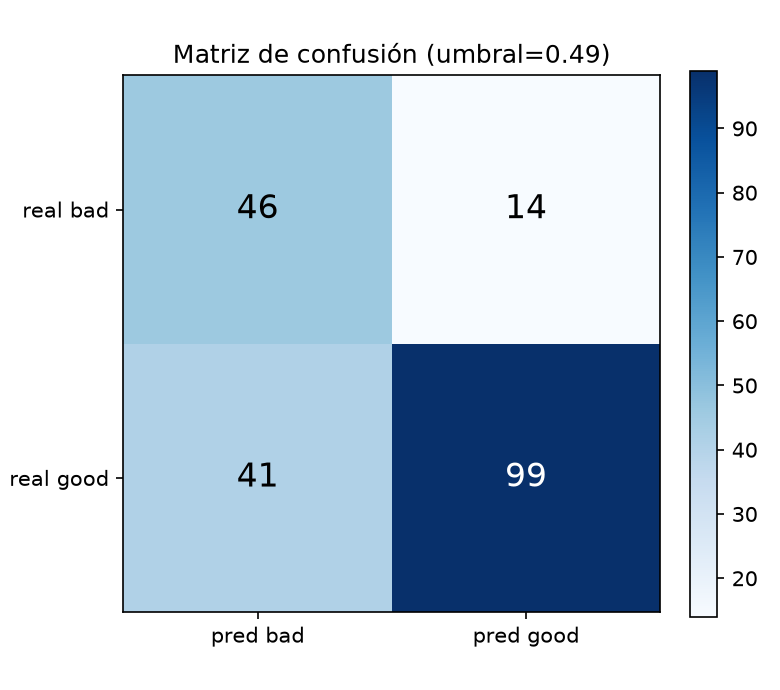

In [8]:
probas, nombres = cla.probas_todos(X_train, y_train, X_test)
rutas = cla.graficar(y_true_bad, proba_test, probas, nombres, umbral, pred_bad, cla.FIG_DIR)
display(Image(filename=rutas[0]))
display(Image(filename=rutas[1]))


**Interpretación de las figuras.** Las tres curvas ROC van pegadas (AUC 0.821–0.835): la elección
del algoritmo importa menos que tener las variables correctas. La matriz de confusión (bad=positiva)
muestra el costo operativo del modelo en test: **46 bad detectados**, 14 escapes, 41 falsas alarmas
y 99 good correctamente aprobados. Traducido a gestión: el modelo filtra el 77 % de los morosos
potenciales a cambio de marcar para revisión el 29 % de los buenos (41/140).


## 7) Reproducción completa y artefactos


In [9]:
salida = cla.main()


=== Comparación por CV estratificada 5-fold (train) ===


              modelo  roc_auc_cv  auc_std  f1_bad_cv
   logistica_bal_C01       0.772    0.044      0.779
   random_forest_bal       0.771    0.033      0.805
    logistica_bal_C1       0.763    0.036      0.767
baseline_mayoritaria       0.500    0.000      0.824

mejor por CV ROC-AUC: logistica_bal_C01



umbral óptimo (F1-bad en CV train): 0.49 (F1=0.599)


=== Métricas en test (umbral óptimo) ===
{'roc_auc_test': 0.835, 'umbral': 0.49, 'precision_bad': 0.529, 'recall_bad': 0.767, 'f1_bad': 0.626}

=== Top 12 variables ===
                          feature  importancia
cat__laufkont_cat_ge200_or_salary        0.709
    cat__laufkont_cat_no_checking        0.636
            cat__verw_cat_car_new        0.543
     cat__moral_cat_all_bank_paid        0.518
        cat__sparkont_cat_unknown        0.466
             cat__verw_cat_others        0.462
          cat__beszeit_cat_4_to_7        0.407
    cat__sparkont_cat_500_to_1000        0.352
             cat__gastarb_cat_yes        0.350
              cat__gastarb_cat_no        0.350
          cat__moral_cat_critical        0.333
                    num__laufzeit        0.331



figuras: ['docs\\modelos\\figuras\\roc_curvas.png', 'docs\\modelos\\figuras\\matriz_confusion.png']
metricas guardadas: modelos\clasificacion\metricas.json


## 8) Conclusión de la clasificación

Una regresión logística regularizada y balanceada alcanza **ROC-AUC 0.835 en test (0.77 en CV)**
detectando el 77 % de los créditos malos. El estado de la cuenta corriente y el historial crediticio
— las dos variables que el Data Mart señaló como más discriminantes — encabezan el modelo.
Limitaciones: n=1000, datos de 1973–1975 y `hoehe` transformada; el umbral puede recalibrarse según
el costo real de falsas alarmas vs. escapes en la cartera actual.

**Siguiente:** Unidad IV (clustering y PCA) en los notebooks 05–06.
